# Figure 0: funky heatmap prototype

This notebook builds method-by-metric tables for the deconvolution benchmark summary:

- raw metrics, with `NaN` when a method/metric is missing
- normalized metric scores, scaled independently per metric so the best method is `1` and the worst is `0`
- category scores, where each category is the sum of its metric scores divided by the number of metrics in that category
- an overall score, computed as the sum of category scores and used to sort methods

Finally, robustness to unknown content contributed two metrics: the all-cells RMSE and correlation values computed across all cell types within each pseudobulk replicate, dataset, and unknown-content fraction. Replicate-level values were averaged within each dataset and unknown-content fraction, and the heatmap used the mean of these all-cells summary values per method.

Lower-is-better metrics (`RMSE`, runtime, memory, spillover) are flipped before scoring; correlation is kept higher-is-better. Missing metric scores contribute `0` to their category score.

Raw metrics: /Users/berni/PycharmProjects/rectangle_paper/data/fig0/funky_heatmap_raw_metrics.csv
Normalized scores: /Users/berni/PycharmProjects/rectangle_paper/data/fig0/funky_heatmap_scores.csv
Category scores: /Users/berni/PycharmProjects/rectangle_paper/data/fig0/funky_heatmap_category_scores.csv
Long metrics: /Users/berni/PycharmProjects/rectangle_paper/data/fig0/funky_heatmap_long_metrics.csv
Prototype figure: /Users/berni/PycharmProjects/rectangle_paper/figures/fig6.pdf
Raw shape: (9, 21)
Score shape: (9, 28)
Category score shape: (9, 7)


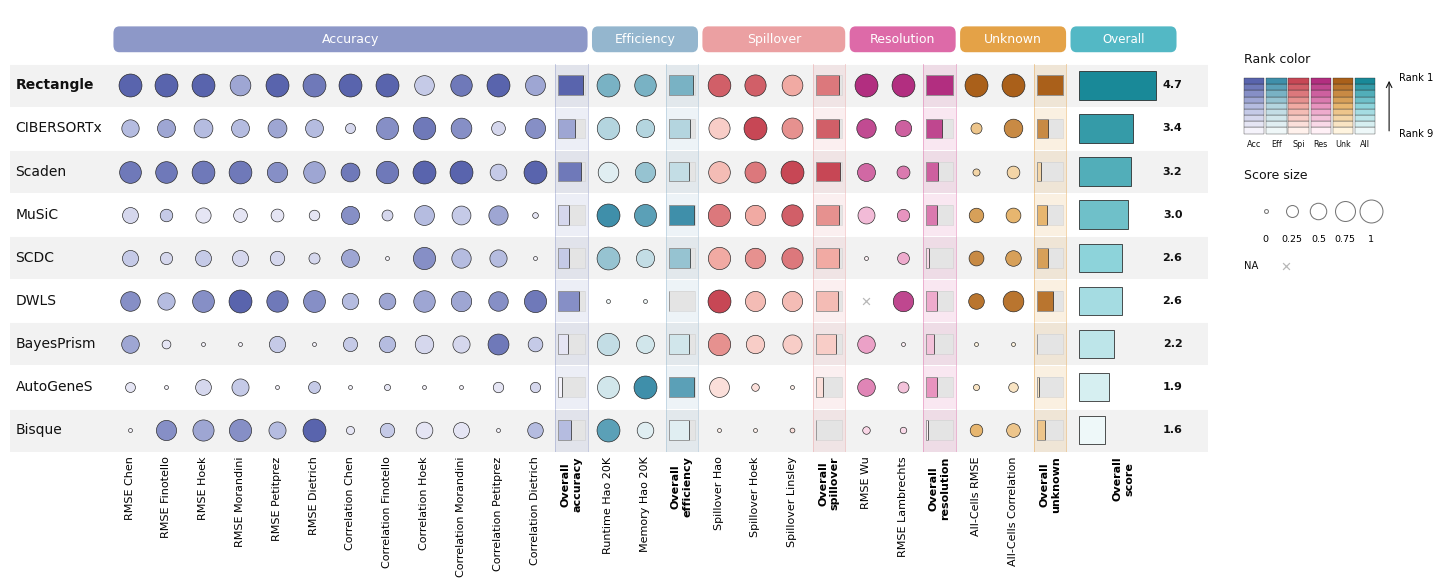

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "scripts").exists() else cwd.parent
scripts_dir = project_root / "scripts"
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))

from build_fig0_funky_heatmap import (
    CATEGORY_SCORE_TABLE_PATH,
    FIGURE_PATH,
    LONG_TABLE_PATH,
    RAW_TABLE_PATH,
    SCORE_TABLE_PATH,
    build_all,
)

raw_metrics, score_metrics, category_scores, long_metrics, fig, ax = build_all()

print(f"Raw metrics: {RAW_TABLE_PATH}")
print(f"Normalized scores: {SCORE_TABLE_PATH}")
print(f"Category scores: {CATEGORY_SCORE_TABLE_PATH}")
print(f"Long metrics: {LONG_TABLE_PATH}")
print(f"Prototype figure: {FIGURE_PATH}")
print(f"Raw shape: {raw_metrics.shape}")
print(f"Score shape: {score_metrics.shape}")
print(f"Category score shape: {category_scores.shape}")

## Category and overall scores

In [2]:
category_scores

,score_accuracy,score_efficiency,score_spillover,score_resolution,score_unknown,overall_score,overall_score_scaled
method,,,,,,,
Rectangle,0.929825,0.938057,0.880724,1.000000,1.000000,4.748606,0.949721
CIBERSORTx,0.637885,0.795331,0.893090,0.601996,0.288657,3.216958,0.643392
Scaden,0.878011,0.787530,0.907600,0.449020,0.100968,3.123129,0.624626
MuSiC,0.412308,0.958433,0.863995,0.403435,0.352936,2.991107,0.598221
SCDC,0.421301,0.806828,0.859891,0.122722,0.374020,2.584762,0.516952
DWLS,0.770206,0.000000,0.842987,0.392659,0.488374,2.494227,0.498845
BayesPrism,0.370240,0.774681,0.756789,0.286887,0.040099,2.228695,0.445739
AutoGeneS,0.151106,0.958024,0.275140,0.393061,0.011742,1.789073,0.357815
Bisque,0.499111,0.754593,0.004979,0.067169,0.235519,1.561371,0.312274


## Raw metric table

In [3]:
raw_metrics

,accuracy_rmse_chen,accuracy_rmse_finotello,accuracy_rmse_hoek,accuracy_rmse_morandini,accuracy_rmse_petitprez,accuracy_rmse_dietrich,accuracy_corr_chen,accuracy_corr_finotello,accuracy_corr_hoek,accuracy_corr_morandini,...,accuracy_corr_dietrich,runtime_hao_20k_s,memory_hao_20k_mib,spillover_pct_hao,spillover_pct_hoek,spillover_pct_linsley,resolution_rmse_wu,resolution_rmse_lambrechts,unknown_rmse_all,unknown_corr_all
method,,,,,,,,,,,,,,,,,,,,,
Rectangle,0.310972,0.327889,0.267462,0.883645,0.480013,0.628479,0.830599,0.541792,0.635079,0.592625,...,0.508263,33.6,3428.0,9.16,19.78,18.480,0.199153,0.194176,0.025657,0.994296
CIBERSORTx,0.452132,0.633465,0.621013,1.116615,0.709404,0.925938,0.302937,0.510611,0.823676,0.551238,...,0.514920,482.7,7838.0,18.62,10.54,17.290,0.566925,0.548353,0.161611,0.592277
Scaden,0.345741,0.417584,0.281774,0.692714,0.636789,0.711917,0.616379,0.520480,0.856897,0.672581,...,0.665454,2261.2,5281.0,15.78,20.85,5.122,0.700022,0.689140,0.190655,0.462731
MuSiC,0.482625,0.885129,0.876313,1.398407,0.970736,1.219707,0.589264,0.171524,0.647580,0.461530,...,0.060129,13.0,2729.0,10.95,24.22,15.290,0.780347,0.708170,0.145312,0.614806
SCDC,0.478331,0.896005,0.827996,1.246980,0.910366,1.203383,0.573152,0.077354,0.798772,0.484386,...,0.038825,94.7,8044.0,11.94,23.80,15.702,1.450473,0.726433,0.142475,0.630823
DWLS,0.400640,0.671593,0.378703,0.674623,0.575246,0.698851,0.514098,0.315154,0.755149,0.532705,...,0.620194,11270.6,19195.0,7.34,25.49,21.824,NaN,0.345610,0.131874,0.734141
BayesPrism,0.446756,1.006341,1.324017,1.771133,0.834723,1.356927,0.428039,0.304668,0.565925,0.384405,...,0.283605,575.3,8432.0,11.20,33.43,27.593,0.732497,0.899567,0.189163,0.383210
AutoGeneS,0.579895,1.099673,0.843975,1.175973,1.172802,1.176160,0.196466,0.097402,0.047298,0.037907,...,0.151177,958.1,1236.0,26.66,68.05,76.822,0.727575,0.752554,0.203419,0.397560
Bisque,0.631618,0.511758,0.430410,0.750533,0.796039,0.627999,0.259120,0.252283,0.467279,0.335943,...,0.316673,26.5,10029.0,82.03,73.33,75.751,1.348203,0.862457,0.151762,0.493475


## Normalized score table

In [4]:
score_metrics

,score_accuracy,score_efficiency,score_spillover,score_resolution,score_unknown,overall_score,overall_score_scaled,accuracy_rmse_chen,accuracy_rmse_finotello,accuracy_rmse_hoek,...,accuracy_corr_dietrich,runtime_hao_20k_s,memory_hao_20k_mib,spillover_pct_hao,spillover_pct_hoek,spillover_pct_linsley,resolution_rmse_wu,resolution_rmse_lambrechts,unknown_rmse_all,unknown_corr_all
method,,,,,,,,,,,,,,,,,,,,,
Rectangle,0.929825,0.938057,0.880724,1.000000,1.000000,4.748606,0.949721,1.000000,1.000000,1.000000,...,0.749148,0.998170,0.877944,0.975633,0.852843,0.813696,1.000000,1.000000,1.000000,1.000000
CIBERSORTx,0.637885,0.795331,0.893090,0.601996,0.288657,3.216958,0.643392,0.559764,0.604065,0.665373,...,0.759771,0.958277,0.632385,0.848976,1.000000,0.830293,0.706092,0.497899,0.235189,0.342125
Scaden,0.878011,0.787530,0.907600,0.449020,0.100968,3.123129,0.624626,0.891567,0.883782,0.986454,...,1.000000,0.800295,0.774765,0.887000,0.835802,1.000000,0.599727,0.298313,0.071804,0.130131
MuSiC,0.412308,0.958433,0.863995,0.403435,0.352936,2.991107,0.598221,0.464664,0.277984,0.423739,...,0.033998,1.000000,0.916866,0.951667,0.782131,0.858187,0.535535,0.271335,0.326882,0.378990
SCDC,0.421301,0.806828,0.859891,0.122722,0.374020,2.584762,0.516952,0.478056,0.263893,0.469470,...,0.000000,0.992743,0.620914,0.938412,0.788820,0.852441,0.000000,0.245445,0.342837,0.405202
DWLS,0.770206,0.000000,0.842987,0.392659,0.488374,2.494227,0.498845,0.720353,0.554663,0.894713,...,0.927773,0.000000,0.000000,1.000000,0.761905,0.767057,NaN,0.785319,0.402474,0.574275
BayesPrism,0.370240,0.774681,0.756789,0.286887,0.040099,2.228695,0.445739,0.576529,0.120930,0.000000,...,0.390630,0.950052,0.599310,0.948320,0.635452,0.686597,0.573775,0.000000,0.080197,0.000000
AutoGeneS,0.151106,0.958024,0.275140,0.393061,0.011742,1.789073,0.357815,0.161309,0.000000,0.454347,...,0.179295,0.916048,1.000000,0.741331,0.084090,0.000000,0.577708,0.208414,0.000000,0.023484
Bisque,0.499111,0.754593,0.004979,0.067169,0.235519,1.561371,0.312274,0.000000,0.761761,0.845774,...,0.443401,0.998801,0.510385,0.000000,0.000000,0.014937,0.081730,0.052609,0.290597,0.180441


## Long-format metric table

The long table is convenient for later grouped plotting or an actual `funkyheatmap` export.

In [5]:
long_metrics.head(12)

,method,metric_group,metric,raw_value,score,direction
0,Rectangle,Accuracy,accuracy_rmse_chen,0.310972,1.000000,lower_is_better
1,CIBERSORTx,Accuracy,accuracy_rmse_chen,0.452132,0.559764,lower_is_better
2,Scaden,Accuracy,accuracy_rmse_chen,0.345741,0.891567,lower_is_better
3,MuSiC,Accuracy,accuracy_rmse_chen,0.482625,0.464664,lower_is_better
4,SCDC,Accuracy,accuracy_rmse_chen,0.478331,0.478056,lower_is_better
5,DWLS,Accuracy,accuracy_rmse_chen,0.400640,0.720353,lower_is_better
6,BayesPrism,Accuracy,accuracy_rmse_chen,0.446756,0.576529,lower_is_better
7,AutoGeneS,Accuracy,accuracy_rmse_chen,0.579895,0.161309,lower_is_better
8,Bisque,Accuracy,accuracy_rmse_chen,0.631618,0.000000,lower_is_better
9,Rectangle,Accuracy,accuracy_rmse_finotello,0.327889,1.000000,lower_is_better
